In [2]:
from wget import download
from os import path
import pandas as pd
import numpy as np

if not path.exists('housing_pandas.csv'):
    download('https://ignaciorlando.github.io/datasets/housing_pandas.csv')
else:
    print('File already exists')

leer_datos_boston = pd.read_csv('housing_pandas.csv')
leer_datos_boston.info()

File already exists
<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    float64
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(14)
memory usage: 55.5 KB


In [3]:
leer_datos_boston.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


In [4]:
leer_datos_boston["ZN"].value_counts()

ZN
0.0      372
20.0      21
80.0      15
12.5      10
25.0      10
22.0      10
40.0       7
45.0       6
30.0       6
90.0       5
21.0       4
60.0       4
95.0       4
33.0       4
75.0       3
28.0       3
55.0       3
52.5       3
70.0       3
34.0       3
35.0       3
85.0       2
82.5       2
18.0       1
100.0      1
17.5       1
Name: count, dtype: int64

In [5]:
leer_datos_boston["RAD"] = leer_datos_boston["RAD"].astype(int)
leer_datos_boston["CHAS"] = leer_datos_boston["CHAS"].astype(int)
leer_datos_boston["TAX"] = leer_datos_boston["TAX"].astype(int)

In [6]:
leer_datos_boston.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [7]:
leer_datos_boston.isna().sum()

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

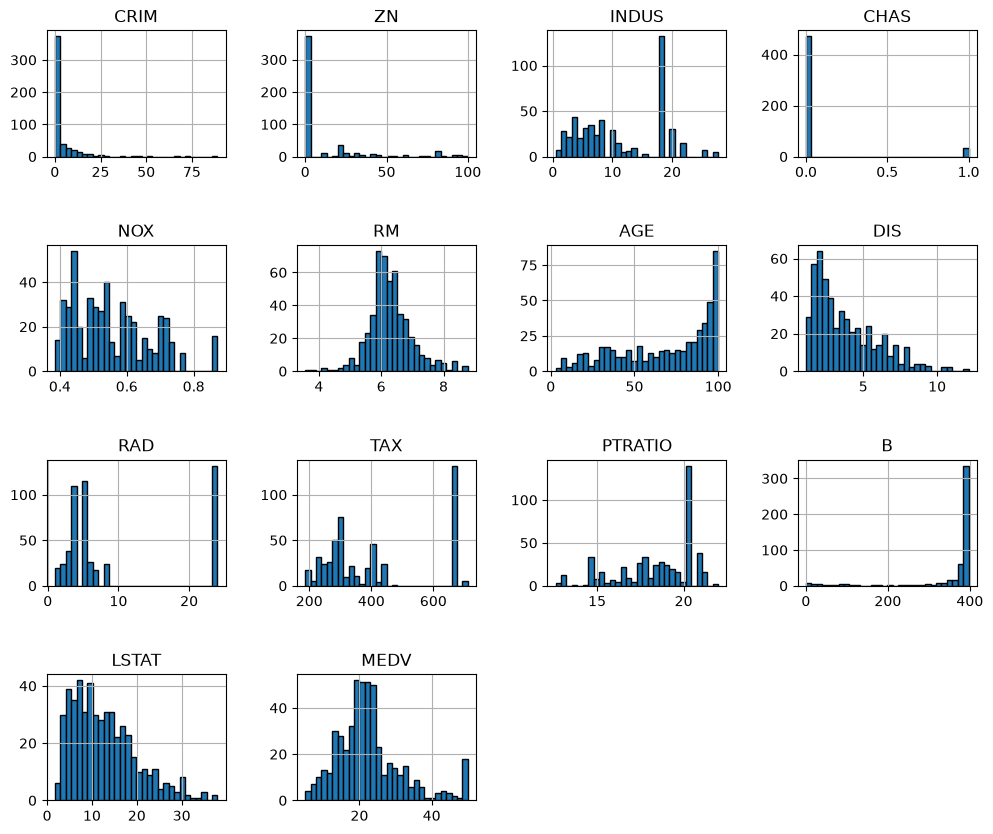

In [8]:
import matplotlib.pyplot as plt

leer_datos_boston.hist(figsize=(12,10), bins=30, edgecolor='black')
plt.subplots_adjust(hspace=0.7, wspace=0.4)

1. CRIM — Tasa de criminalidad per cápita
La distribución presenta una fuerte asimetría hacia la derecha. La mayoría de las observaciones tiene valores cercanos a cero, mientras que unas pocas presentan valores muy elevados. La criminalidad está concentrada en valores bajos para gran parte de las observaciones, pero existen zonas con tasas considerablemente superiores. Podrían existir valores atípicos.

2. ZN — Proporción de terrenos residenciales destinados a lotes grandes
Se observa una gran concentración en cero y algunos grupos de valores positivos, incluso cercanos a 100. En muchas zonas no hay terrenos que cumplan el criterio de tamaño considerado por esta variable. En otras, la proporción es considerablemente mayor. La distribución no es normal.

3. INDUS — Proporción de acres comerciales no minoristas por localidad
Los valores se distribuyen en varios grupos, con una concentración destacada alrededor de 18–19 y otros grupos en valores inferiores.
Las localidades tienen distintos niveles de actividad comercial no minorista. La distribución presenta agrupamientos y no parece seguir una distribución normal.

4. CHAS — Proximidad al río Charles
Es una variable binaria: toma los valores 0 y 1. Casi todas las observaciones tienen valor 0 y una pequeña proporción tiene valor 1.
La mayoría de las zonas no limita con el río Charles. Como es una variable categórica binaria, su distribución se interpreta mediante frecuencias, no como una variable cuantitativa continua.

5. NOX — Concentración de óxidos de nitrógeno
Los valores se encuentran aproximadamente entre 0,38 y 0,87, con varias concentraciones y picos.
Las zonas presentan distintos niveles de contaminación del aire. La distribución no es simétrica y parece mostrar agrupamientos de observaciones.

6. RM — Número medio de habitaciones por vivienda
La mayor concentración se encuentra alrededor de 6 habitaciones. La distribución es aproximadamente unimodal, con una cola hacia los valores más altos.
La mayoría de las viviendas tiene una cantidad media de habitaciones cercana a 6. Hay menos observaciones con viviendas muy pequeñas o con un número elevado de habitaciones.

7. AGE — Proporción de viviendas construidas antes de 1940
Se observa una concentración importante cerca de 100 y una distribución extendida hacia valores inferiores.
En numerosas zonas, una proporción elevada de las viviendas se construyó antes de 1940. La distribución presenta asimetría hacia la izquierda.

8. DIS — Distancias ponderadas a centros de empleo
La mayoría de los valores se concentra aproximadamente entre 2 y 5, con una cola hacia la derecha.
Muchas zonas tienen distancias ponderadas relativamente bajas, mientras que unas pocas presentan distancias considerablemente mayores. La distribución tiene asimetría positiva.

9. RAD — Índice de accesibilidad a autopistas radiales
Se observan concentraciones en valores discretos, con un pico importante en 24.
Muchas observaciones corresponden a zonas con un índice de accesibilidad elevado. Es una variable discreta y su distribución no es uniforme.

10. TAX — Tasa de impuesto a la propiedad
Los valores presentan varios grupos y una concentración importante alrededor de 666.
Las localidades tienen diferentes tasas impositivas, con una acumulación marcada en determinados valores. La distribución es irregular y multimodal, es decir, presenta varios picos.

11. PTRATIO — Relación alumnos/docentes por localidad
La distribución se concentra principalmente entre 18 y 21, con un pico pronunciado cerca de 20.
Gran parte de las localidades presenta relaciones entre alumnos y docentes similares, aunque existen algunas con valores más bajos. La distribución no es perfectamente simétrica.

12. B — Variable transformada relacionada con la composición demográfica
La mayoría de los valores se concentra cerca de 350–400, mientras que hay pocas observaciones con valores muy bajos.
La distribución presenta una fuerte asimetría hacia la izquierda. Es importante recordar que B es una variable transformada utilizada en el conjunto histórico Boston Housing, no una medición directa de una característica de las viviendas.

13. LSTAT — Porcentaje de población de menor nivel socioeconómico
Los valores se concentran principalmente en niveles bajos e intermedios, con una cola que se extiende hacia valores elevados.
La mayoría de las observaciones presenta porcentajes relativamente bajos o moderados, mientras que unas pocas tienen porcentajes elevados. La distribución tiene asimetría positiva.

14. MEDV — Valor mediano de las viviendas ocupadas por sus propietarios
La mayor concentración se encuentra aproximadamente entre 15 y 25, con un pico alrededor de 20–22 y otro grupo de valores en el extremo superior, cerca de 50.
Los valores medianos de las viviendas se concentran en un rango intermedio. El pico cercano a 50 puede deberse al límite superior impuesto a esta variable en el conjunto de datos original, por lo que no necesariamente representa el valor real de todas esas viviendas.

In [9]:
leer_datos_boston.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


- CRIM: presenta una media de 3,61 y una desviación estándar de 8,60, lo que indica una gran dispersión y posibles valores extremos.
- ZN: tiene una media de 11,34, pero su mediana es 0, indicando que al menos la mitad de las observaciones tiene valor cero.
- INDUS: posee una media de 11,14 y una mediana de 9,69, con diferencias entre localidades.
- CHAS: tiene una media de 0,07, lo que indica que aproximadamente el 7 % de las observaciones toma el valor 1.
- NOX: presenta una media de 0,55 y poca dispersión relativa.
- RM: tiene una media de 6,28 habitaciones por vivienda y una mediana de 6,21.
- AGE: presenta una media de 68,57 y una mediana de 77,50, indicando una importante presencia de viviendas antiguas en muchas zonas.
- DIS: tiene una media de 3,80 y una mediana de 3,21, con algunos valores considerablemente superiores.
- RAD: presenta una mediana de 5 y un máximo de 24, mostrando diferencias en la accesibilidad a autopistas.
- TAX: tiene una media de 408,24 y una mediana de 330, con una amplia variabilidad.
- PTRATIO: presenta una media de 18,46 alumnos por docente y valores entre 12,60 y 22.
- B: tiene una media de 356,67 y una mediana de 391,44, con una concentración de valores elevados.
- LSTAT: presenta una media de 12,65 y una mediana de 11,36, con valores que alcanzan 37,97.
- MEDV: tiene una media de 22,53 y una mediana de 21,20, con valores entre 5 y 50.

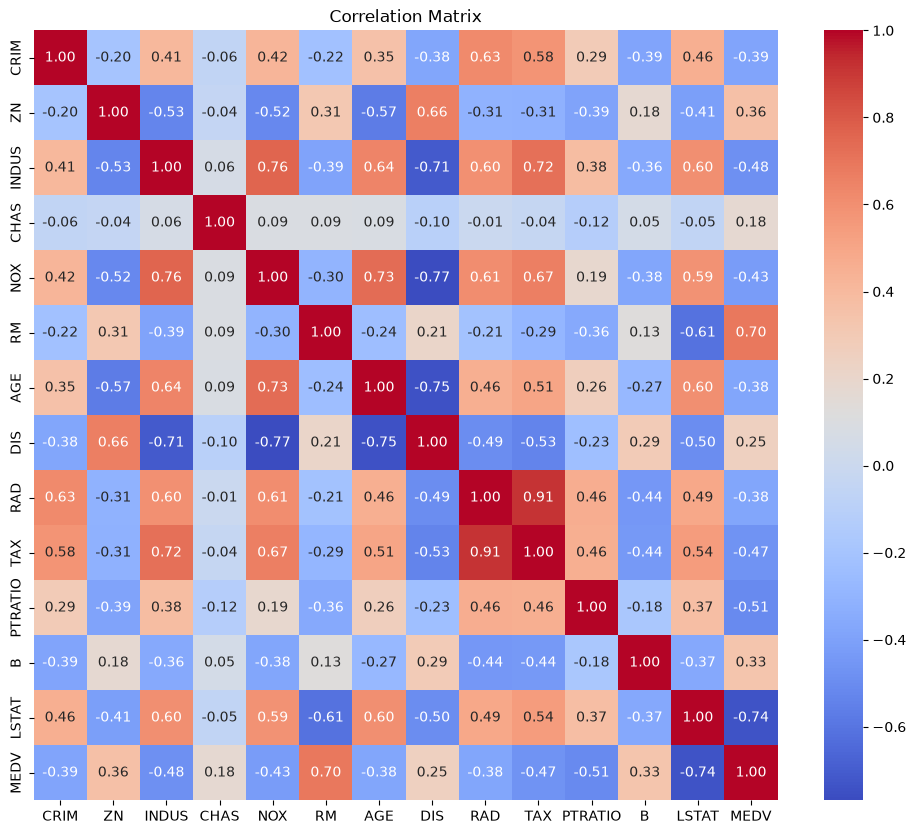

In [10]:
import seaborn as sns

correlation_matrix = leer_datos_boston.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

LSTAT y RM presentan las asociaciones lineales más fuertes con el precio de las viviendas (MEDV), negativa y positiva respectivamente.
Para construir un modelo, podemos elegir inicialmente RM y LSTAT, porque ambas presentan una correlación importante con MEDV y representan características diferentes: el número medio de habitaciones y el porcentaje de población de menor nivel socioeconómico.

RM         0.695360
ZN         0.360445
B          0.333461
DIS        0.249929
CHAS       0.175260
AGE       -0.376955
RAD       -0.381626
CRIM      -0.388305
NOX       -0.427321
TAX       -0.468536
INDUS     -0.483725
PTRATIO   -0.507787
LSTAT     -0.737663
Name: MEDV, dtype: float64


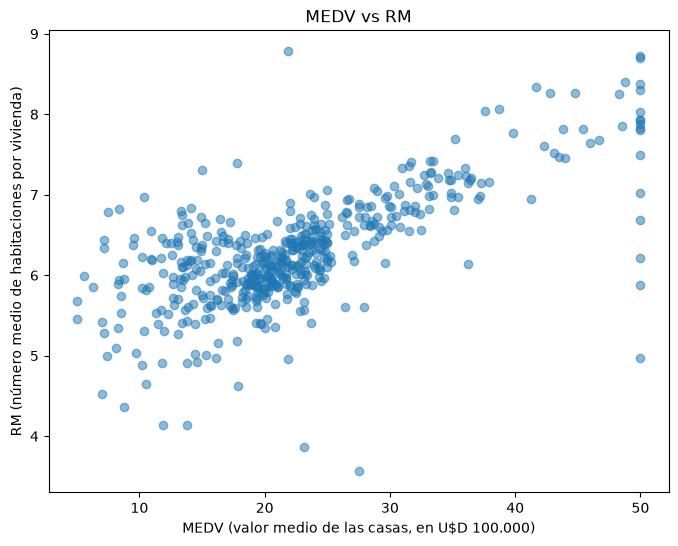

In [11]:
correlaciones = leer_datos_boston.corr(numeric_only=True)["MEDV"].drop("MEDV")
correlaciones = correlaciones.sort_values(ascending=False)

print(correlaciones)
plt.figure(figsize=(8, 6))
plt.scatter(leer_datos_boston['MEDV'], leer_datos_boston['RM'], alpha=0.5)
plt.xlabel('MEDV (valor medio de las casas, en U$D 100.000)')
plt.ylabel('RM (número medio de habitaciones por vivienda)')
plt.title('MEDV vs RM')
plt.show()

Aunque hay una correlación de 0.69 entre MEDV y RM, el scatter plot muestra una gran dispersión, especialmente en valores altos de MEDV. Se ve que en las casas de U$D 500.000 hay medianas de ingresos que oscilan practicamente por todo el rango, un comportamiento bastante extraño.


In [12]:
import statsmodels.api as sm

# Separamos nuestra variable independiente
X = leer_datos_boston['RM']
# y nuestra variable objetivo (variable dependiente)
y = leer_datos_boston['MEDV']

# Agregamos una constante como característica, para estimar la ordenada al origen
X = sm.add_constant(X)
# Ajustamos el modelo
model = sm.OLS(y, X).fit()
# Imprimimos el resumen de los resultados
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.484
Model:                            OLS   Adj. R-squared:                  0.483
Method:                 Least Squares   F-statistic:                     471.8
Date:                Mon, 26 Oct 2026   Prob (F-statistic):           2.49e-74
Time:                        09:23:38   Log-Likelihood:                -1673.1
No. Observations:                 506   AIC:                             3350.
Df Residuals:                     504   BIC:                             3359.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -34.6706      2.650    -13.084      0.0

R^2 de 0.484. Esto indica que el modelo explica aproximadamente el 48.4% de la varianza de RM a partir de MEDV. Esto sugiere que MEDV es un predictor que puede andar bien, pero que aún falta mucha varianza sin explicar, posiblemente debido a otros factores no incluidos en el modelo, o a ruido que no hemos podido capturar.

El p-valor (de F) es recontra bajo, lo que indica que el modelo en su conjunto es significativo. Esto implica que RM es útil para predecir MEDV con una confianza estadística alta.

El coeficiente de 9,1021 indica que, por cada habitación adicional en el promedio, el valor mediano estimado de la vivienda aumenta aproximadamente 9,10 mil dólares, según el modelo lineal. Esto se debe a que MEDV está expresada en miles de dólares en el conjunto de datos original. Este coeficiente también es muy significativo (p < 0.001), lo que confirma la fuerte asociación entre ambas variables. Si miramos el rango, vemos que no incluye al 0. Esto es una buena noticia.

La constante es -34.6706, lo que representa el valor medio estimado de las casas cuando MedInc es cero. Aunque en un contexto real este valor no tenga un significado directo (porque no tiene sentido que no tenga habitaciones), ayuda a ajustar la línea de regresión.

El estadístico Omnibus analiza si hay desviaciones significativas en la asimetría y curtosis con respecto a la normalidad. Un p-valor bajo (p<0.05) sugiere que los residuos no son normales.

El test de Jarque-Bera también estudia la asimetría y la curtosis, pero usa una metodología diferente. Su p-valor está marcado como Prob(JB), y también es bajo.

En este caso, un valor de 0.655 (Durbin-Watson) indica una autocorrelación positiva, lo que puede implicar que los errores no son completamente independientes entre sí. En un contexto de datos espaciales (como los datos de vivienda de Boston), esto podría deberse a patrones geográficos no modelados adecuadamente.

En este caso, ambos valores de AIC y BIC son relativamente altos, a pesar de que estamos usando una única variable independiente. Esto puede deberse a que las estimaciones de L sean erroneas producto de la no normalidad de los supuestos.


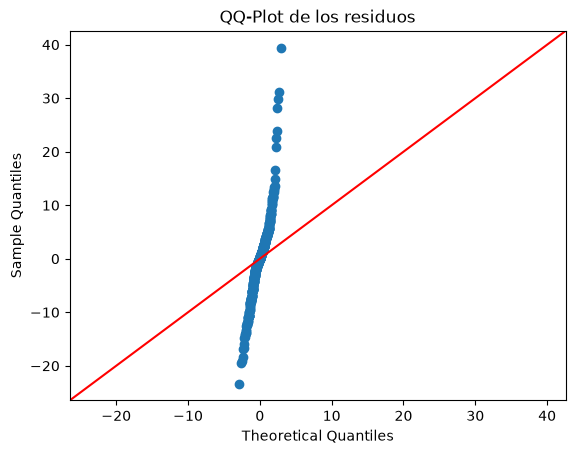

In [13]:
model.resid
# QQ-Plot
sm.qqplot(model.resid, line='45')
plt.title("QQ-Plot de los residuos")
plt.show()

Vemos que la silueta es bastante horrenda: no tenemos una semejanza a la recta de la diagonal, por lo que todo parece indicar que los residuos no respetan una distribución normal.

In [14]:
from scipy.stats import shapiro

# aplicamos Shapiro-Wilk sobre los residuos
_, p = shapiro(model.resid)
print("p = %.4f" % (p))
# comparamos con el alpha
alpha = 0.05
if p > alpha:
    print("Se distribuyen normal (falló en rechazarse la hipótesis nula)")
else:
    print('No se distribuyen normal (se rechazó la hipótesis nula)')

p = 0.0000
No se distribuyen normal (se rechazó la hipótesis nula)


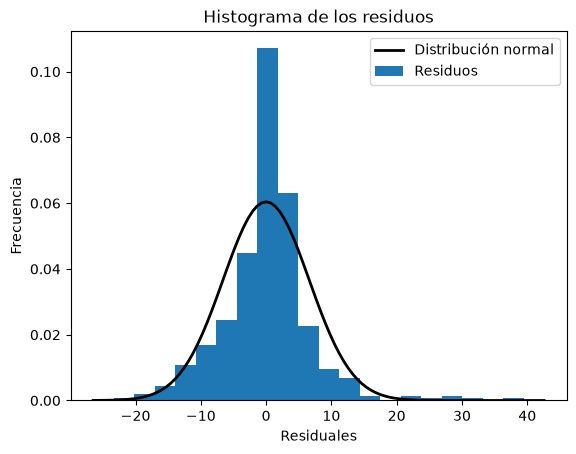

In [15]:
from scipy.stats import norm

# Histograma de residuos
plt.hist(model.resid, bins=20, density=True)
# Ajustamos una curva normal a esos residuos
mu, std = norm.fit(model.resid)
# Graficamos la curva de la distribución normal
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
plt.plot(x, p, 'k', linewidth=2)

plt.xlabel("Residuales")
plt.ylabel("Frecuencia")
plt.title("Histograma de los residuos")
plt.legend(["Distribución normal", "Residuos"])
plt.show()

Se ve que aunque hay una silueta "acampanada", tenemos un desplazamiento leve hacia valores posotivos, y una cola (la de la izquierda) bastante disimil respecto a una distribución normal. Tiene sentido, entonces, que los tests nos hayan dicho que no hay normalidad de residuos.

Los resultados de las pruebas Omnibus y Jarque-Bera, entonces, indican que los residuales no siguen una distribución normal (p < 0.001 en ambos casos).

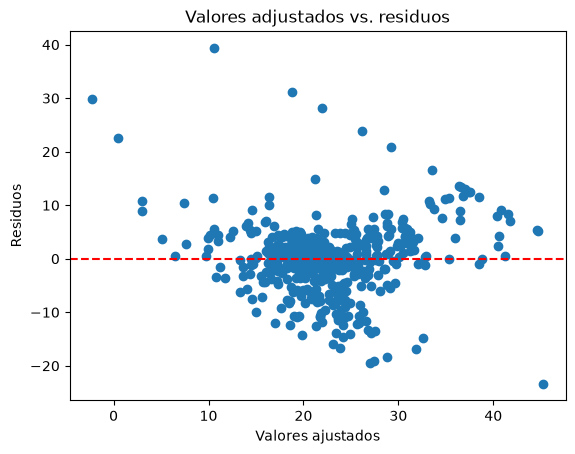

In [16]:
plt.scatter(model.fittedvalues, model.resid)
plt.xlabel("Valores ajustados")
plt.ylabel("Residuos")
plt.title("Valores adjustados vs. residuos")
plt.axhline(0, color='red', linestyle='--')
plt.show()

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Seleccionar las variables explicativas y la variable objetivo
X = leer_datos_boston[["RM", "LSTAT"]]
y = leer_datos_boston["MEDV"]

# Dividir los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Crear y entrenar el modelo
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Realizar predicciones
y_pred = modelo.predict(X_test)

# Mostrar la ecuación estimada
print("Intercepto:", modelo.intercept_)
print("Coeficientes:", modelo.coef_)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:", r2_score(y_test, y_pred))

Intercepto: -3.8411770790048827
Coeficientes: [ 5.46509877 -0.63249856]
MAE: 3.8987597213823584
RMSE: 5.589569804715174
R²: 0.5739577415025858


- Coeficientes: indican cómo cambia la predicción cuando una variable aumenta una unidad, manteniendo constante la otra.
- MAE: representa el error absoluto medio entre los precios reales y los predichos. Cuanto menor sea, mejor.
- RMSE: mide el error cuadrático medio en la misma unidad que MEDV, penalizando más los errores grandes.
- R²: indica qué proporción de la variabilidad de los precios explica el modelo en los datos evaluados. Cuanto más se acerque a 1, mayor será la capacidad explicativa.

In [18]:
from sklearn.preprocessing import StandardScaler

# Separar la variable objetivo (MEDV) de las variables predictoras
X = leer_datos_boston.drop('MEDV', axis=1)
y = leer_datos_boston['MEDV']

# Estandarizar las variables predictoras
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
# Metamoslo en un dataframe así no perdemos los nombres de las columnas
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

In [19]:
# Imprimir las medias y desviaciones estándar antes del escalado
print("Medias y desviaciones estándar antes del escalado:")
print(pd.DataFrame(X).describe().loc[['mean', 'std']])

# Imprimir las medias y desviaciones estándar después del escalado
print("\nMedias y desviaciones estándar después del escalado:")
print(pd.DataFrame(X_scaled_df).describe().loc[['mean', 'std']])

Medias y desviaciones estándar antes del escalado:
          CRIM         ZN      INDUS      CHAS       NOX        RM        AGE  \
mean  3.613524  11.363636  11.136779  0.069170  0.554695  6.284634  68.574901   
std   8.601545  23.322453   6.860353  0.253994  0.115878  0.702617  28.148861   

           DIS       RAD         TAX    PTRATIO           B      LSTAT  
mean  3.795043  9.549407  408.237154  18.455534  356.674032  12.653063  
std   2.105710  8.707259  168.537116   2.164946   91.294864   7.141062  

Medias y desviaciones estándar después del escalado:
              CRIM            ZN         INDUS          CHAS           NOX  \
mean -1.123388e-16  7.898820e-17  2.106352e-16 -3.510587e-17 -1.965929e-16   
std   1.000990e+00  1.000990e+00  1.000990e+00  1.000990e+00  1.000990e+00   

                RM           AGE           DIS           RAD      TAX  \
mean -1.088282e-16 -1.474446e-16 -8.425408e-17 -1.123388e-16  0.00000   
std   1.000990e+00  1.000990e+00  1.000990e+00  1.0

In [20]:
# Agregamos una constante como característica, para estimar la ordenada al origen
X_scaled_df_ = sm.add_constant(X_scaled_df)
# Ajustamos el modelo
model = sm.OLS(y, X_scaled_df_).fit()
# Imprimimos el resumen de los resultados
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.741
Model:                            OLS   Adj. R-squared:                  0.734
Method:                 Least Squares   F-statistic:                     108.1
Date:                Mon, 26 Oct 2026   Prob (F-statistic):          6.72e-135
Time:                        09:23:41   Log-Likelihood:                -1498.8
No. Observations:                 506   AIC:                             3026.
Df Residuals:                     492   BIC:                             3085.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         22.5328      0.211    106.814      0.0

Vemos que el coeficiente de determinación en este caso es 0.741, contra 0.484 que teníamos antes. Esto implica que estamos ajustando mejor que como lo hacíamos antes, porque estamos explican un 74.1% de la variación en MEDV, cuando antes solamente capturábamos el 48.4%.
Esta mejora sugiere, entonces, que estas variables adicionales realmente aportan información útil al modelo, y que ayudan a capturar mejor la variabilidad en la mediana de valor de las casas.
El p-valor, que sigue siendo bajo. Esto indica que el modelo nuevo también es significativo en su conjunto.


El estadístico de Durbin-Watson es ahora 1.078, lo cual sigue sugiriendo una autocorrelación positiva entre los residuales, mayor que la del modelo anterior (donde era 0.684). Esto podría ser debido a que, aunque el modelo captura mejor algunas de las relaciones espaciales en los datos con las nuevas variables, queda mucha dependencia entre los residuos por capturar, producto de ese mismo error sistemático que vemos en la gráfica de valores ajustados vs residuos.

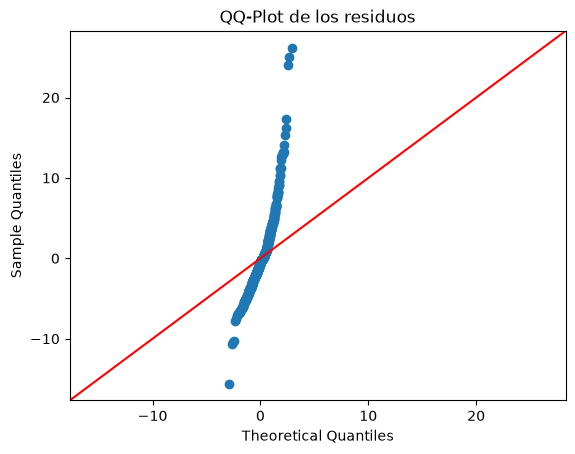

In [21]:
# QQ-Plot
sm.qqplot(model.resid, line='45')
plt.title("QQ-Plot de los residuos")
plt.show()

In [22]:
# aplicamos Shapiro-Wilk sobre los residuos
_, p = shapiro(model.resid)
print("p = %.4f" % (p))
# comparamos con el alpha
alpha = 0.05
if p > alpha:
    print("Se distribuyen normal (falló en rechazarse la hipótesis nula)")
else:
    print('No se distribuyen normal (se rechazó la hipótesis nula)')

p = 0.0000
No se distribuyen normal (se rechazó la hipótesis nula)


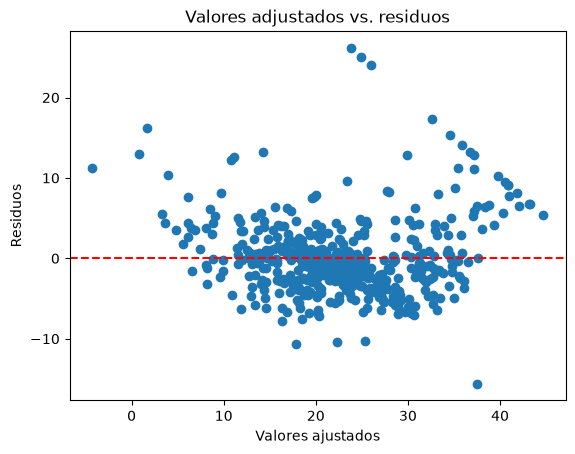

In [23]:
plt.scatter(model.fittedvalues, model.resid)
plt.xlabel("Valores ajustados")
plt.ylabel("Residuos")
plt.title("Valores adjustados vs. residuos")
plt.axhline(0, color='red', linestyle='--')
plt.show()

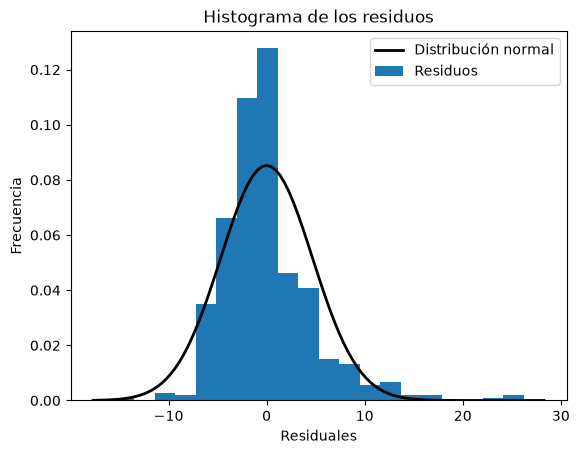

In [24]:
# Histograma de residuos
plt.hist(model.resid, bins=20, density=True)
# Ajustamos una curva normal a esos residuos
mu, std = norm.fit(model.resid)
# Graficamos la curva de la distribución normal
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
plt.plot(x, p, 'k', linewidth=2)

plt.xlabel("Residuales")
plt.ylabel("Frecuencia")
plt.title("Histograma de los residuos")
plt.legend(["Distribución normal", "Residuos"])
plt.show()

# Ejercicio 2

In [25]:
if not path.exists('Life-Expectancy-Data-Updated.csv'):
    download('https://ignaciorlando.github.io/datasets/data-science/Life-Expectancy-Data-Updated.csv')
else:
    print('File already exists')

leer_datos_life = pd.read_csv('Life-Expectancy-Data-Updated.csv')
leer_datos_life.info()

File already exists
<class 'pandas.DataFrame'>
RangeIndex: 2864 entries, 0 to 2863
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Country                      2864 non-null   str    
 1   Region                       2864 non-null   str    
 2   Year                         2864 non-null   int64  
 3   Infant_deaths                2864 non-null   float64
 4   Under_five_deaths            2864 non-null   float64
 5   Adult_mortality              2864 non-null   float64
 6   Alcohol_consumption          2864 non-null   float64
 7   Hepatitis_B                  2864 non-null   int64  
 8   Measles                      2864 non-null   int64  
 9   BMI                          2864 non-null   float64
 10  Polio                        2864 non-null   int64  
 11  Diphtheria                   2864 non-null   int64  
 12  Incidents_HIV                2864 non-null   float64
 13  GDP_per_c

{2: 0.4385163849012986, 3: 0.36624743915387414, 4: 0.3229994483146144, 5: 0.2751407096099383, 6: 0.24999084939826918}


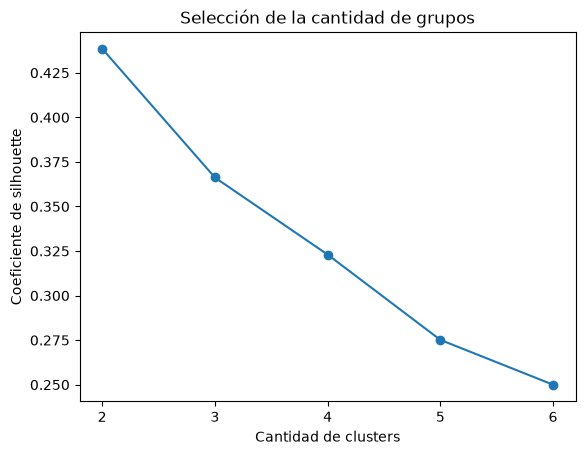

In [26]:
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

datos_paises = (leer_datos_life.sort_values("Year").groupby("Country", as_index=False).tail(1).reset_index(drop=True))
variables = [
    "Life_expectancy",
    "Adult_mortality",
    "Infant_deaths",
    "Alcohol_consumption",
    "BMI",
    "GDP_per_capita",
    "Schooling"
]

X = datos_paises[variables].copy()

# Reemplazar infinitos por valores faltantes
X = X.replace([float("inf"), float("-inf")], float("nan"))

# Imputar faltantes con la mediana
imputador = SimpleImputer(strategy="median")
X_imputado = imputador.fit_transform(X)

# Estandarizar las variables
escalador = StandardScaler()
X_scaled = escalador.fit_transform(X_imputado)

resultados = {}

for k in range(2, 7):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_scaled)
    resultados[k] = silhouette_score(X_scaled, etiquetas)

print(resultados)

plt.plot(list(resultados.keys()), list(resultados.values()), marker="o")
plt.xlabel("Cantidad de clusters")
plt.ylabel("Coeficiente de silhouette")
plt.title("Selección de la cantidad de grupos")
plt.xticks(range(2, 7))
plt.show()


                   Country  Cluster
0        Brunei Darussalam        0
1             Saudi Arabia        0
6             Turkmenistan        0
7              Philippines        0
12   Micronesia, Fed. Sts.        0
..                     ...      ...
137                 Latvia        2
144               Bulgaria        2
174                  Spain        2
161                 Norway        2
163                  Qatar        2

[179 rows x 2 columns]
Cluster
0    82
1    55
2    42
Name: count, dtype: int64


Text(0.5, 1.0, 'Agrupamiento de países según salud, economía y educación')

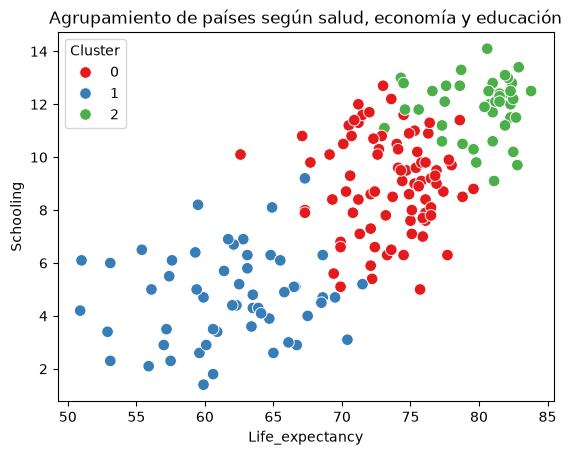

In [27]:
modelo = KMeans(n_clusters=3, random_state=42, n_init=10)

datos_paises["Cluster"] = modelo.fit_predict(X_scaled)

# Mostrar los países y el grupo asignado
print(datos_paises[["Country", "Cluster"]].sort_values("Cluster"))

# Cantidad de países por grupo
print(datos_paises["Cluster"].value_counts().sort_index())

# Visualización de los grupos
sns.scatterplot(
    data=datos_paises,
    x="Life_expectancy",
    y="Schooling",
    hue="Cluster",
    palette="Set1",
    s=70
)

plt.title("Agrupamiento de países según salud, economía y educación")

In [28]:
print(
    datos_paises.groupby("Cluster")[variables]
    .mean()
    .round(2)
)

         Life_expectancy  Adult_mortality  Infant_deaths  Alcohol_consumption  \
Cluster                                                                         
0                  73.50           138.46          15.17                 3.89   
1                  61.87           265.38          50.92                 2.66   
2                  80.05            79.69           4.10                 9.08   

           BMI  GDP_per_capita  Schooling  
Cluster                                    
0        26.74         7364.46       8.99  
1        23.16         1851.91       4.71  
2        26.55        36970.36      11.91  



Correlaciones del grupo 0:
Adult_mortality       -0.822
Infant_deaths         -0.699
BMI                   -0.187
Schooling             -0.008
Alcohol_consumption    0.050
GDP_per_capita         0.366
Name: Life_expectancy, dtype: float64


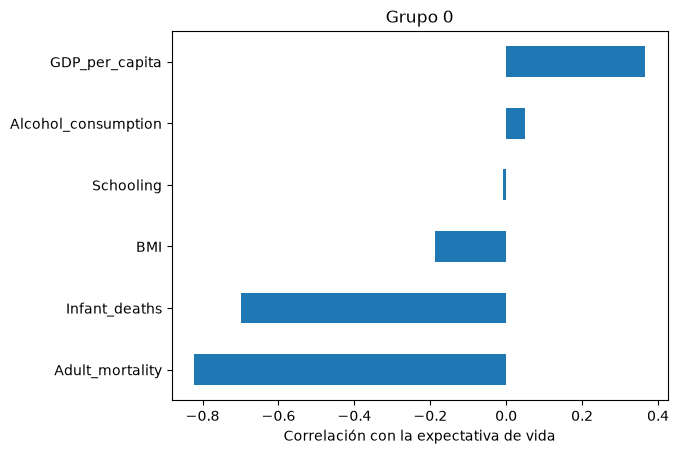


Correlaciones del grupo 1:
Adult_mortality       -0.888
Infant_deaths         -0.809
BMI                   -0.218
Alcohol_consumption   -0.159
GDP_per_capita         0.083
Schooling              0.129
Name: Life_expectancy, dtype: float64


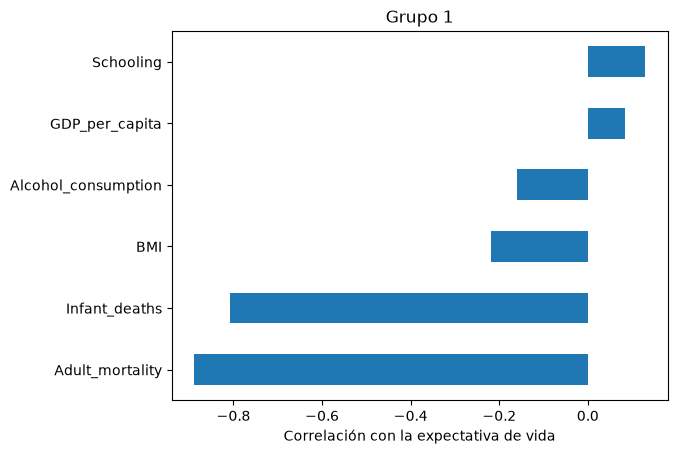


Correlaciones del grupo 2:
Adult_mortality       -0.927
Infant_deaths         -0.537
BMI                   -0.416
Alcohol_consumption   -0.302
Schooling             -0.001
GDP_per_capita         0.558
Name: Life_expectancy, dtype: float64


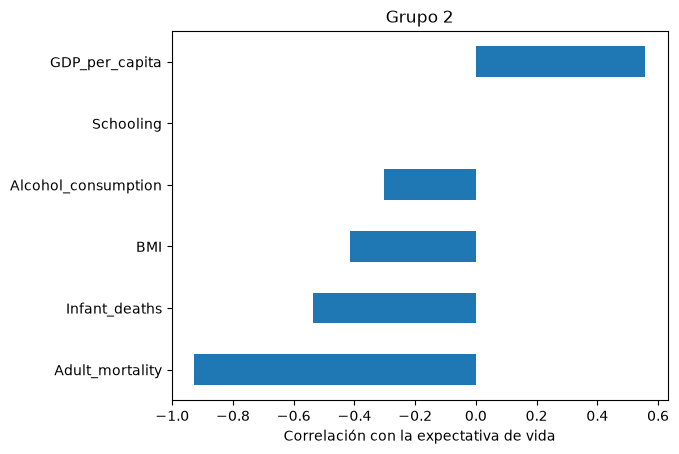

In [30]:
variables_predictoras = [
    "Adult_mortality",
    "Infant_deaths",
    "Alcohol_consumption",
    "BMI",
    "GDP_per_capita",
    "Schooling"
]

for grupo in sorted(datos_paises["Cluster"].unique()):
    datos_grupo = datos_paises[datos_paises["Cluster"] == grupo]

    correlaciones = (
        datos_grupo[variables_predictoras + ["Life_expectancy"]]
        .corr()["Life_expectancy"]
        .drop("Life_expectancy")
        .sort_values()
    )

    print(f"\nCorrelaciones del grupo {grupo}:")
    print(correlaciones.round(3))

    correlaciones.plot(kind="barh", title=f"Grupo {grupo}")
    plt.xlabel("Correlación con la expectativa de vida")
    plt.show()

- Una correlación positiva indica que ambas variables tienden a aumentar juntas.
- Una correlación negativa indica que, cuando una aumenta, la otra tiende a disminuir.
- Cuanto más se acerque el valor absoluto a 1, más fuerte es la relación lineal.

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Crear un DataFrame con los datos imputados y los clusters
datos_modelo = datos_paises[["Country", "Cluster"]].copy()
datos_modelo[variables] = X_imputado

objetivo = "Life_expectancy"

predictoras = [
    "Adult_mortality",
    "Infant_deaths",
    "Alcohol_consumption",
    "BMI",
    "GDP_per_capita",
    "Schooling"
]

resultados_modelos = []

for grupo in sorted(datos_modelo["Cluster"].unique()):

    datos_grupo = datos_modelo[
        datos_modelo["Cluster"] == grupo
    ].copy()

    if len(datos_grupo) < 10:
        print(f"Grupo {grupo}: insuficientes observaciones.")
        continue

    X = datos_grupo[predictoras]
    y = datos_grupo[objetivo]

    # Dividir los datos del grupo en entrenamiento y prueba
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42
    )

    # Seleccionar las 3 variables más correlacionadas
    correlaciones_train = (
        X_train.join(y_train)
        .corr()[objetivo]
        .drop(objetivo)
        .dropna()
    )

    mejores_variables = (
        correlaciones_train.abs()
        .sort_values(ascending=False)
        .head(3)
        .index.tolist()
    )

    # Entrenar el modelo
    modelo = LinearRegression()
    modelo.fit(X_train[mejores_variables], y_train)

    # Predecir
    y_pred = modelo.predict(X_test[mejores_variables])

    # Evaluar
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    resultados_modelos.append({
        "Cluster": grupo,
        "Cantidad de países": len(datos_grupo),
        "Variables seleccionadas": ", ".join(mejores_variables),
        "R2": r2,
        "MAE": mae,
        "RMSE": rmse
    })

    print(f"\nGrupo {grupo}")
    print("Variables seleccionadas:", mejores_variables)
    print("Intercepto:", round(modelo.intercept_, 3))
    print("Coeficientes:", dict(zip(
        mejores_variables,
        modelo.coef_.round(3)
    )))
    print("R²:", round(r2, 3))
    print("MAE:", round(mae, 3))
    print("RMSE:", round(rmse, 3))

# Comparación final
tabla_resultados = pd.DataFrame(resultados_modelos)
display(tabla_resultados.round(3))


Grupo 0
Variables seleccionadas: ['Adult_mortality', 'Infant_deaths', 'GDP_per_capita']
Intercepto: 81.392
Coeficientes: {'Adult_mortality': np.float64(-0.046), 'Infant_deaths': np.float64(-0.132), 'GDP_per_capita': np.float64(0.0)}
R²: 0.762
MAE: 1.313
RMSE: 1.728

Grupo 1
Variables seleccionadas: ['Adult_mortality', 'Infant_deaths', 'Alcohol_consumption']
Intercepto: 79.449
Coeficientes: {'Adult_mortality': np.float64(-0.036), 'Infant_deaths': np.float64(-0.151), 'Alcohol_consumption': np.float64(-0.081)}
R²: 0.917
MAE: 1.039
RMSE: 1.245

Grupo 2
Variables seleccionadas: ['Adult_mortality', 'GDP_per_capita', 'Infant_deaths']
Intercepto: 85.854
Coeficientes: {'Adult_mortality': np.float64(-0.069), 'GDP_per_capita': np.float64(0.0), 'Infant_deaths': np.float64(-0.172)}
R²: 0.903
MAE: 0.504
RMSE: 0.582


,Cluster,Cantidad de países,Variables seleccionadas,R2,MAE,RMSE
0,0,82,"Adult_mortality, Infant_deaths, GDP_per_capita",0.762,1.313,1.728
1,1,55,"Adult_mortality, Infant_deaths, Alcohol_consum...",0.917,1.039,1.245
2,2,42,"Adult_mortality, GDP_per_capita, Infant_deaths",0.903,0.504,0.582


- R^2 Cuanto más cercano a 1, mayor capacidad explicativa en el conjunto de prueba. Puede ser negativo si el modelo predice peor que usar la media.
- MAE	Error absoluto medio, medido en años de expectativa de vida. Cuanto menor, mejor.
- RMSE	Error que penaliza más las predicciones muy alejadas de los valores reales. También se mide en años.